In [2]:
import zipfile
import pandas as pd
import dask
import dask.dataframe as dd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

with zipfile.ZipFile('card_transactions.zip', 'r') as z:
    z.extractall('.')

df = dd.read_parquet('card_transactions/*.parquet')

In [3]:
df.head()

,amnt,currency,operation_kind,card_type,operation_type,operation_type_group,ecommerce_flag,payment_system,income_flag,mcc,country,city,mcc_category,day_of_week,hour,weekofyear,hour_diff,client_id
0,0.465425,1,4,98,4,2,3,7,3,2,1,37,2,4,19,34,-1,5feceb
1,0.000000,1,2,98,7,1,3,7,3,2,1,49,2,4,20,34,0,5feceb
2,0.521152,1,2,98,3,1,3,7,3,2,1,37,2,4,20,34,0,5feceb
3,0.356078,1,1,5,2,1,3,7,3,10,1,49,7,2,0,34,52,5feceb
4,0.000000,1,2,98,7,1,3,7,3,2,1,49,2,4,16,53,280,5feceb


In [4]:
df.dtypes

amnt                    float64
currency                  int32
operation_kind            int32
card_type                 int32
operation_type            int32
operation_type_group      int32
ecommerce_flag            int32
payment_system            int32
income_flag               int32
mcc                       int32
country                   int32
city                      int32
mcc_category              int32
day_of_week               int32
hour                      int32
weekofyear                int32
hour_diff                 int64
client_id                string
dtype: object

In [5]:
df['day_of_week'].unique().compute()

0    2
1    5
2    3
0    7
0    1
0    4
1    6
Name: day_of_week, dtype: int32

In [6]:
g = df.groupby('client_id')
mean_amount = g['amnt'].mean()
total_amount = g['amnt'].sum()
transaction_count = g.size()
transaction_count

Dask Series Structure:
npartitions=1
    int64
      ...
Dask Name: size, 2 expressions
Expr=Size(frame=ReadParquetFSSpec(9759143), observed=True)

In [7]:
def n_unique(col):
    return (df[['client_id', col]].drop_duplicates().groupby('client_id')[col].count())

In [8]:
cols = ['currency', 'operation_kind', 'operation_type', 'card_type',
        'operation_type_group', 'payment_system', 'mcc', 'country', 'city']
uniq = {f'{col}_n': n_unique(col) for col in cols}    

In [9]:
ecommerce_share = (df['ecommerce_flag'] == 1).groupby(df['client_id']).mean()
income_share  = (df['income_flag'] == 1).groupby(df['client_id']).mean()
weekend_share = (df['day_of_week'] >= 5).groupby(df['client_id']).mean()

g = df.groupby('client_id')
hour_diff_mean = g['hour_diff'].mean()
active_weeks = n_unique('weekofyear')
trans_per_week = transaction_count / active_weeks

In [10]:
features = {
    'mean_amount': mean_amount,
    'total_anount': total_amount,
    'transaction_count': transaction_count,
    'currency_n': n_unique('currency'),
    **uniq,
    'ecommerce_share': ecommerce_share,
    'income_share' : weekend_share,
    'hour_diff_mean': hour_diff_mean,
    'trans_per_week': trans_per_week,
}
results = dask.compute(*features.values())
X = pd.concat(results, axis=1, keys=features.keys())
X['hour_diff_mean'] = X['hour_diff_mean'].fillna(0)

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Text(0, 0.5, 'inertia')

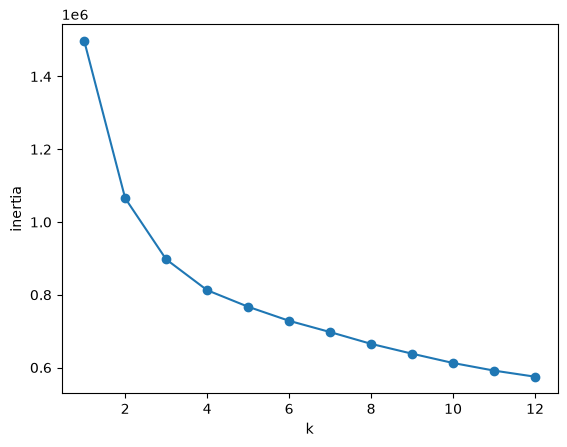

In [ ]:
sample = X_scaled[::10]
inertia = []
for k in range(1, 13):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(sample)
    inertia.append(km.inertia_)

plt.plot(range(1, 13), inertia, marker='o')
plt.xlabel('k'); plt.ylabel('inertia')

In [16]:
kmeans = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
kmeans.fit(X_scaled)
X['cluster'] = kmeans.labels_ + 1

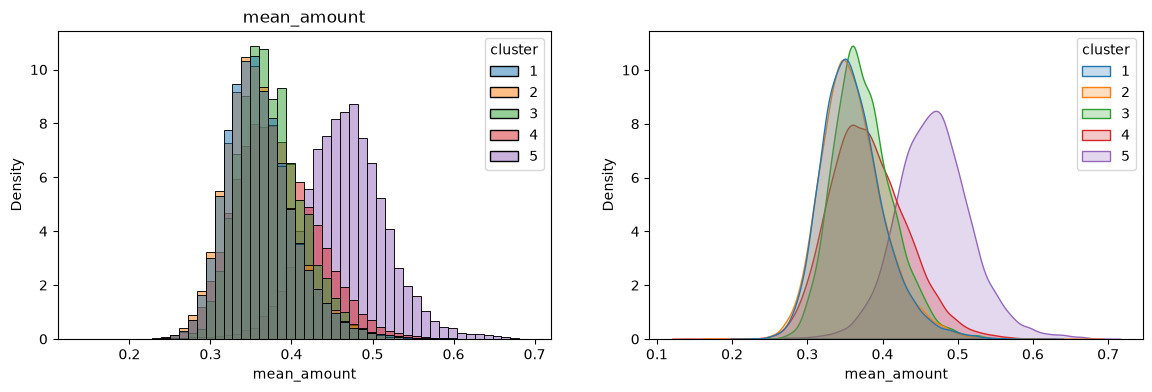

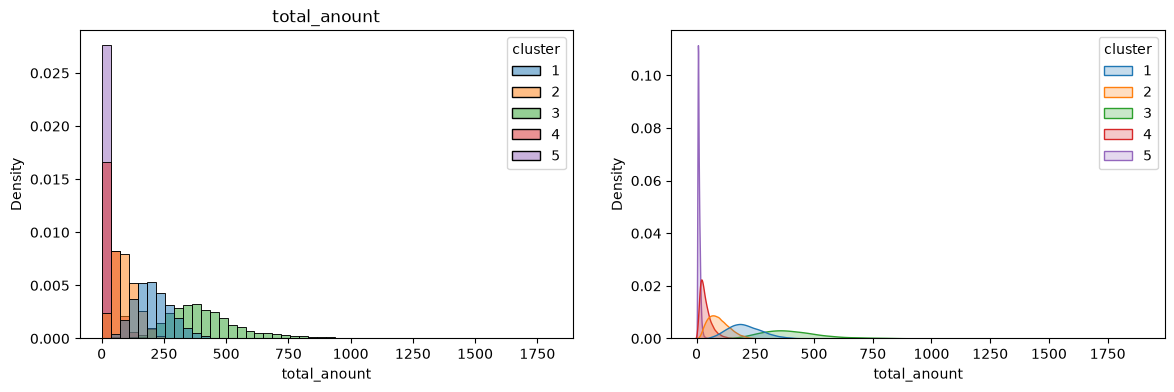

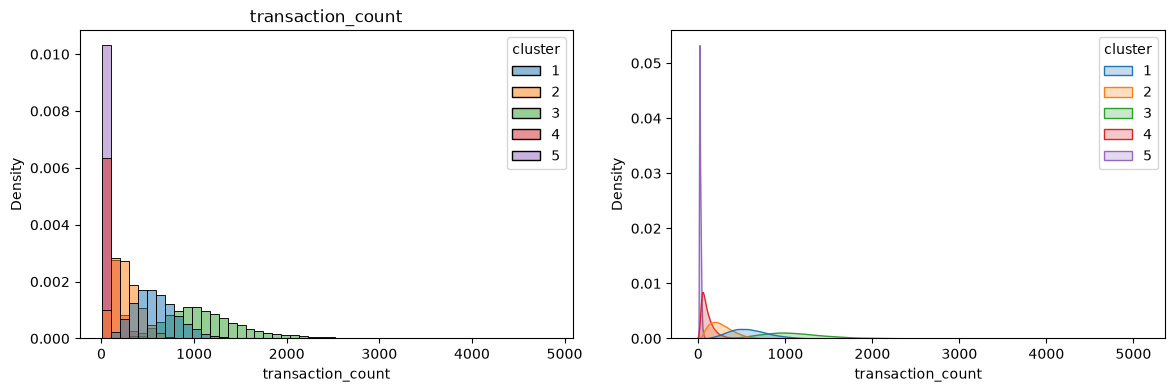

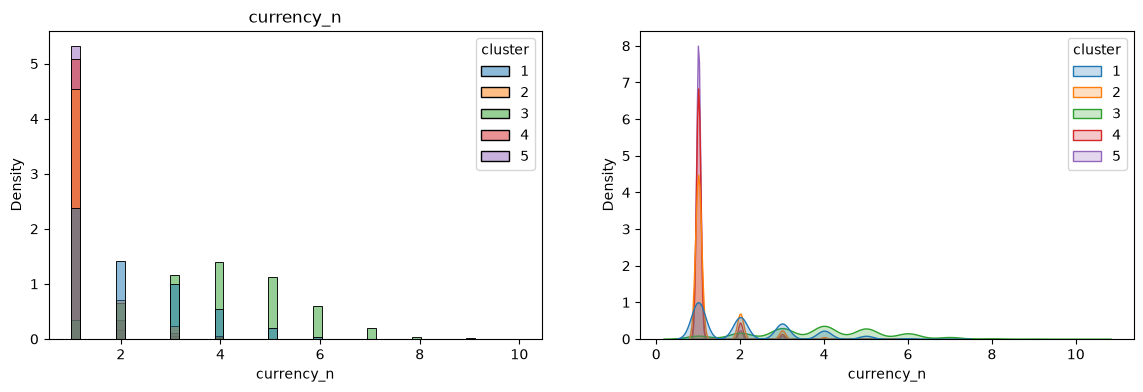

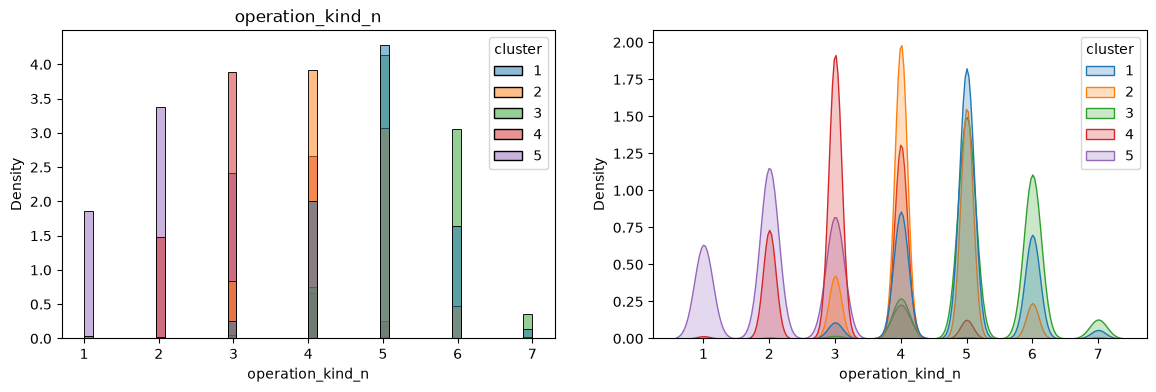

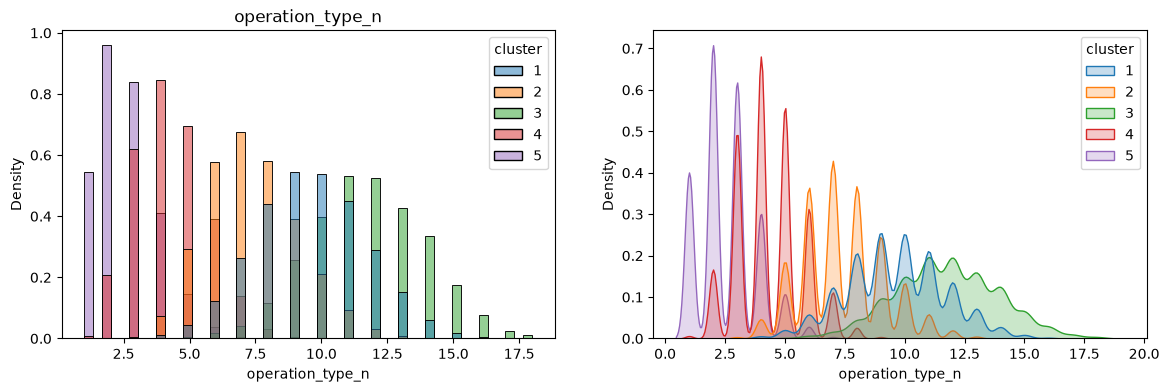

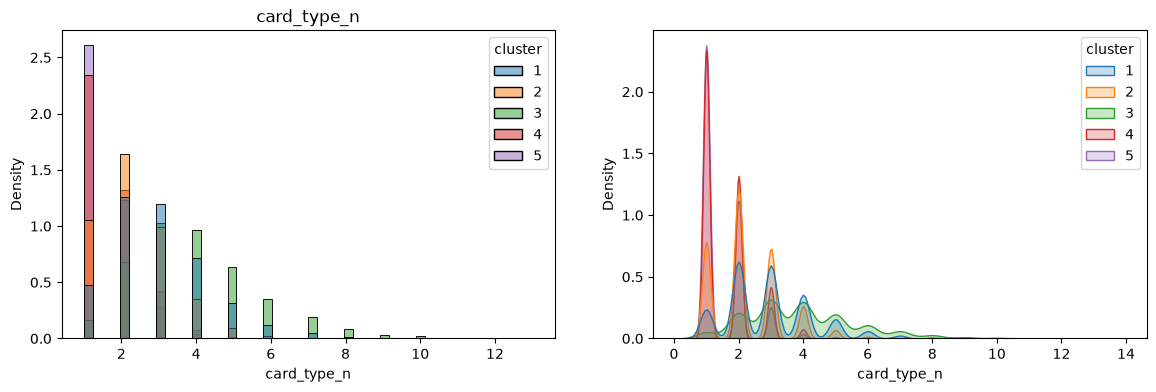

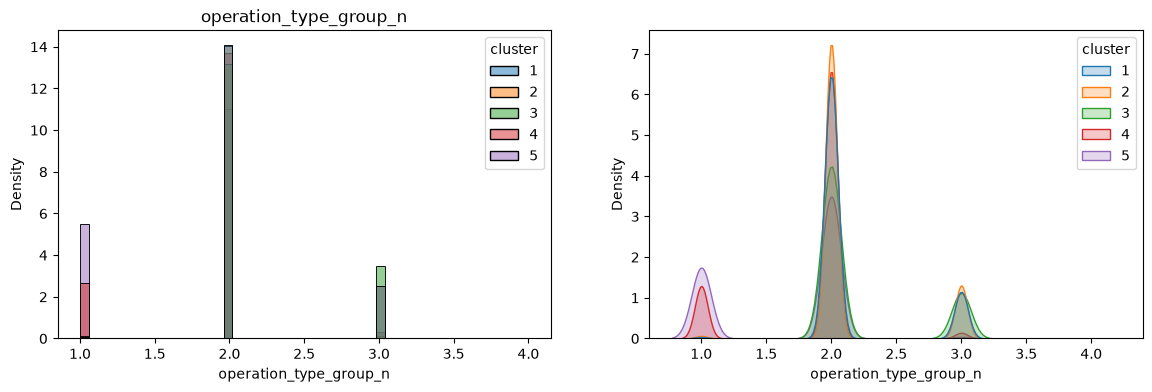

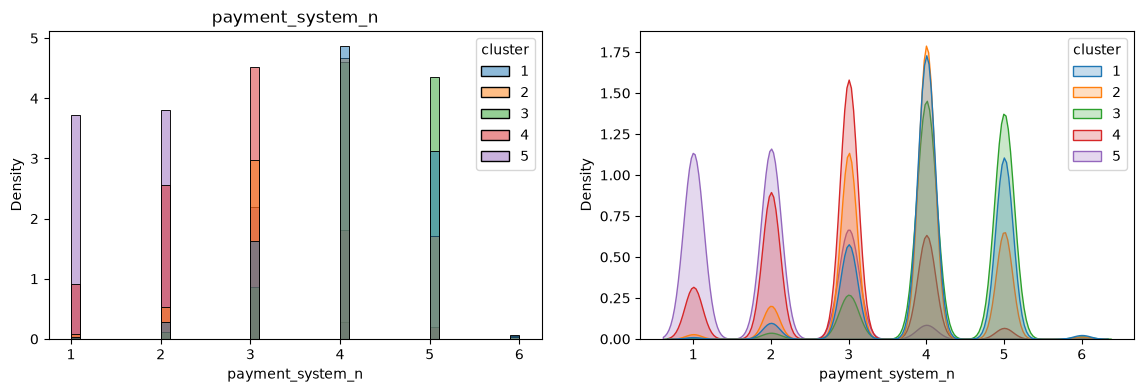

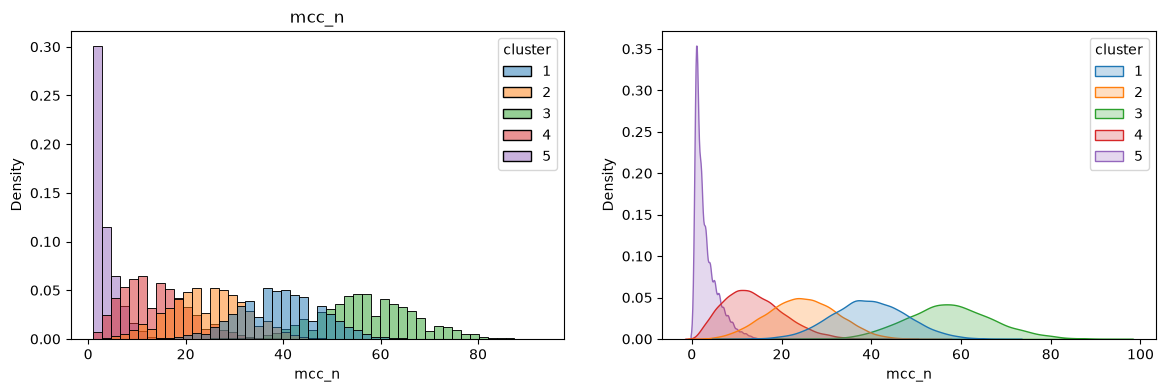

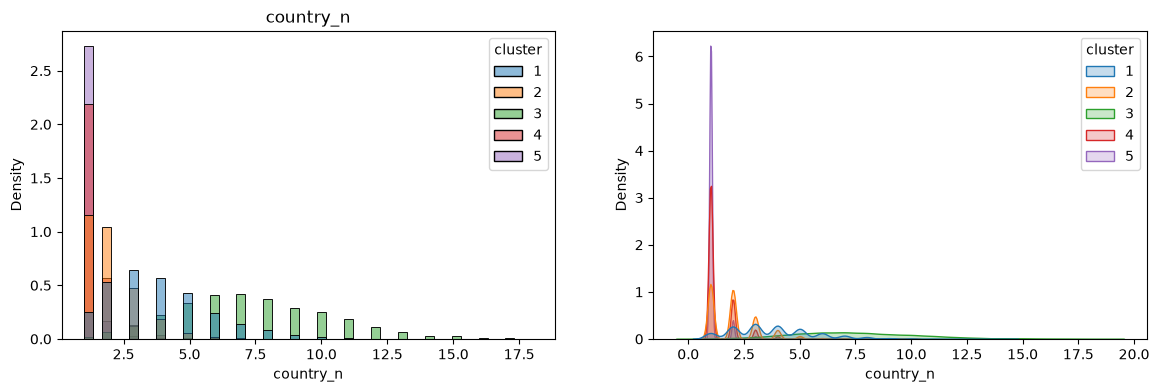

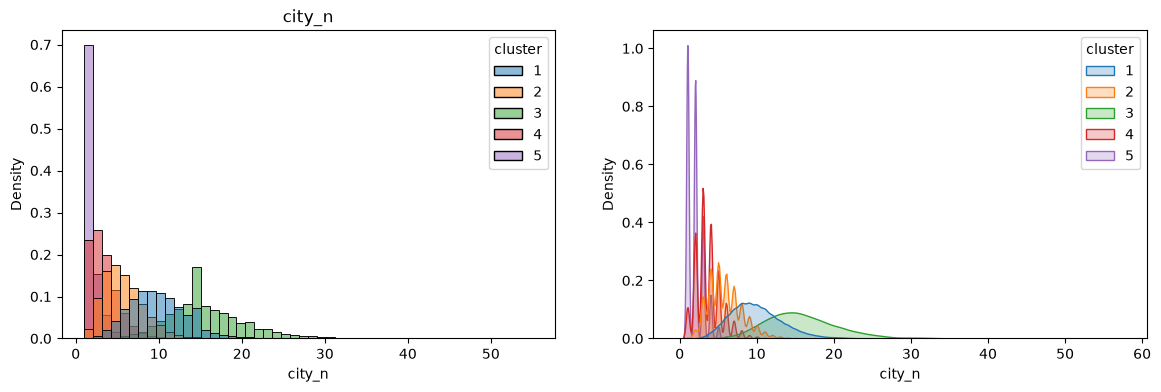

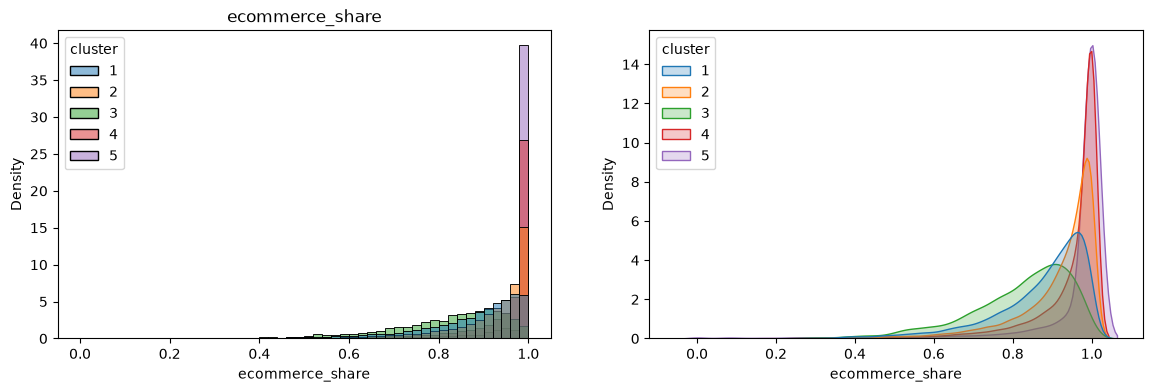

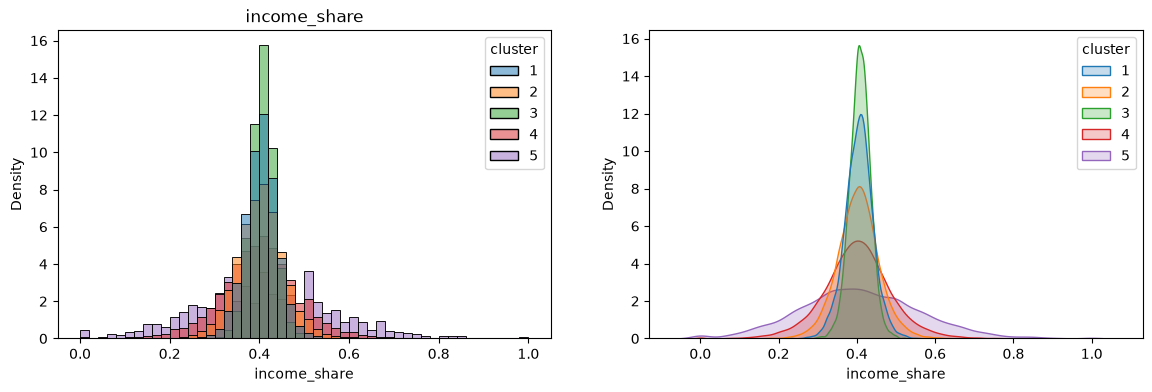

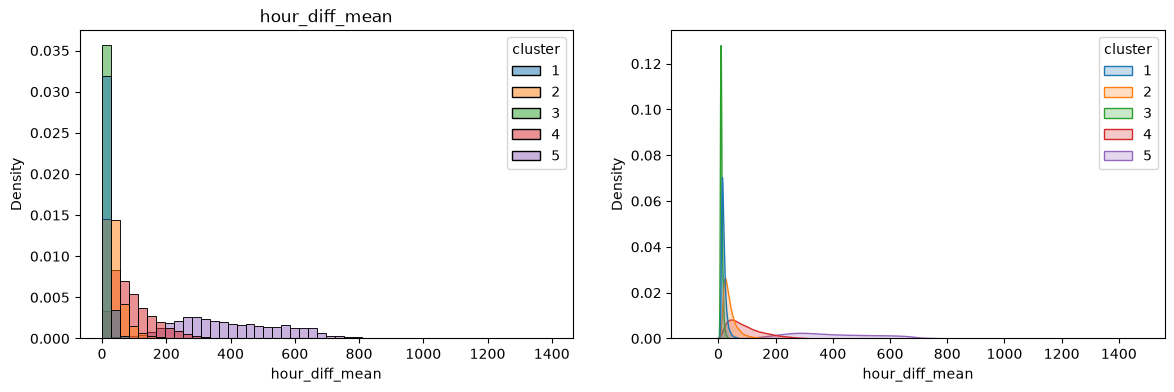

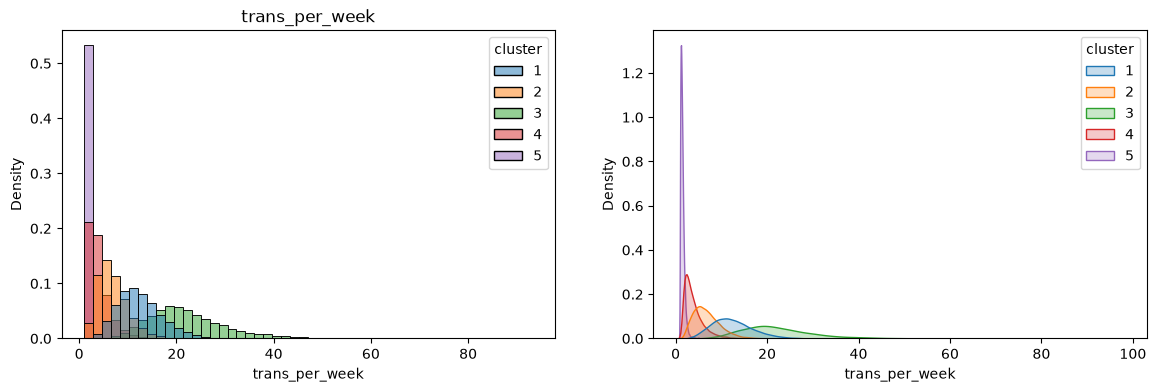

In [17]:
feature_cols = [c for c in X.columns if c != 'cluster']
plot_df = X.sample(100_000, random_state=42)

for col in feature_cols:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(data=plot_df, x=col, hue='cluster', stat='density',
                 common_norm=False, bins=50, palette='tab10', ax=ax[0])
    sns.kdeplot(data=plot_df, x=col, hue='cluster',
                common_norm=False, fill=True, palette='tab10', ax=ax[1])
    ax[0].set_title(col)
    plt.show()

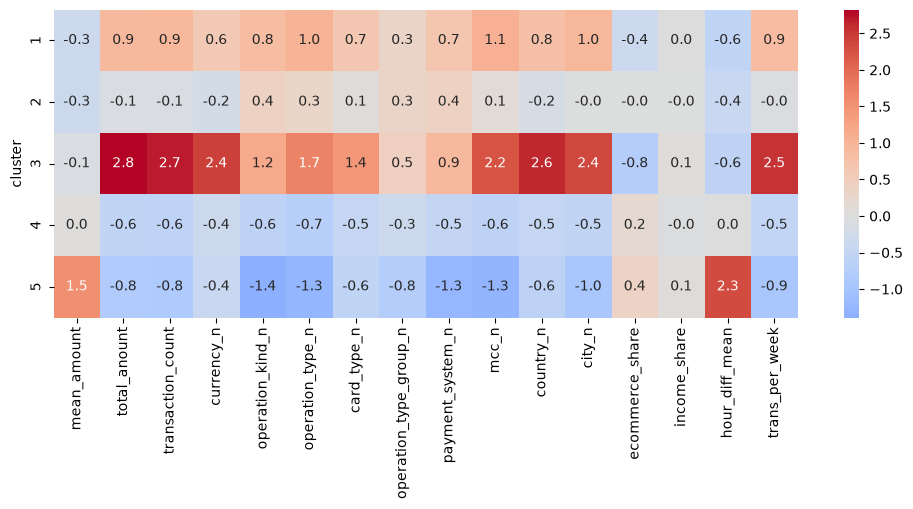

In [18]:
feature_cols = [c for c in X.columns if c != 'cluster']

sizes = X['cluster'].value_counts(normalize=True).sort_index()
medians = X.groupby('cluster')[feature_cols].median()

means = X.groupby('cluster')[feature_cols].mean()
z = (means - X[feature_cols].mean()) / X[feature_cols].std()

plt.figure(figsize=(12, 4))
sns.heatmap(z, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.show()

In [19]:
X.groupby('cluster').median()
X.groupby('cluster').mean()
X['cluster'].value_counts(normalize=True)

cluster
2    0.336691
4    0.324799
1    0.178851
5    0.109349
3    0.050311
Name: proportion, dtype: float64

In [20]:
print(sizes)
print(medians)
print(z.round(1))


cluster
1    0.178851
2    0.336691
3    0.050311
4    0.324799
5    0.109349
Name: proportion, dtype: float64
         mean_amount  total_anount  transaction_count  currency_n  \
cluster                                                             
1           0.356076    199.100092              561.0         2.0   
2           0.356489     86.545324              241.0         1.0   
3           0.371076    394.042917             1074.0         4.0   
4           0.377392     31.351937               82.0         1.0   
5           0.466170      7.765912               17.0         1.0   

         operation_kind_n  operation_type_n  card_type_n  \
cluster                                                    
1                     5.0              10.0          3.0   
2                     4.0               7.0          2.0   
3                     5.0              12.0          4.0   
4                     3.0               4.0          1.0   
5                     2.0               2.0  

NameError: name 'df' is not defined